# Analyse exploratoire des données – attrition des abonnés

Avant de construire un modèle, je cherche à comprendre les données : leur qualité, la répartition
de la cible, les variables qui distinguent les clients partis des clients restés, et la stabilité
des données dans le temps. Les constats de ce notebook justifient les choix faits dans les scripts
du Bloc 5 (découpage temporel, mesures, construction et sélection des variables).

**Source** : export de la table `gold.variables_clients` produit par `bloc1/exporter_gold.py`
(une ligne par client et par date de référence, clients pseudonymisés).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from config import CIBLE, fichier_donnees
from donnees import charger
from variables import construire

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (9, 4)

print("Fichier analysé :", fichier_donnees())
df = charger()

Fichier analysé : c:\Users\Admin\Desktop\Projet_Attrition_KODJO\bloc5\..\bloc1\exports\variables_clients_2026-10-30.csv


## 1. Aperçu général

In [2]:
print(f"{len(df)} lignes, {df.shape[1]} colonnes")
print(f"{df['client_pseudo'].nunique()} clients distincts, "
      f"{df['date_reference'].nunique()} dates de référence "
      f"(du {df['date_reference'].min().date()} au {df['date_reference'].max().date()})")
df.head()

38495 lignes, 16 colonnes
4839 clients distincts, 11 dates de référence (du 2025-11-01 au 2026-09-01)


,client_pseudo,date_reference,plan_code,prix_mensuel,anciennete_jours,sessions_30j,sessions_30_60j,evolution_sessions,supports_30j,reclamations_30j,jours_depuis_derniere_session,code_departement,taille_commune,resiliation_30j,calcule_le,run_id
0,00186ac7-b885-42b3-b244-344830e6347e,2025-11-01,ESS,9.99,77,12,0,NaN,0,0,2.0,69,grande,0,2026-10-30 05:07:06.568981+00:00,10
1,001e999c-0083-4001-bd3f-ec7ea18e2c64,2025-11-01,ESS,9.99,64,5,1,4.0,0,0,3.0,44,petite,0,2026-10-30 05:07:06.568981+00:00,10
2,001f52de-e455-4645-b0d2-1b29a66e8438,2025-11-01,CONF,14.99,621,3,0,NaN,0,0,2.0,33,grande,0,2026-10-30 05:07:06.568981+00:00,10
3,002187cf-3f3b-4f54-8b7d-734027375221,2025-11-01,ESS,9.99,377,24,0,NaN,0,0,1.0,44,petite,0,2026-10-30 05:07:06.568981+00:00,10
4,00729b6f-ac3c-4cf5-a807-4f03303c0022,2025-11-01,CONF,14.99,518,16,0,NaN,1,1,2.0,44,petite,0,2026-10-30 05:07:06.568981+00:00,10


In [3]:
df.dtypes.to_frame("type")

,type
client_pseudo,object
date_reference,datetime64[ns]
plan_code,object
prix_mensuel,float64
anciennete_jours,int64
sessions_30j,int64
sessions_30_60j,int64
evolution_sessions,float64
supports_30j,int64
reclamations_30j,int64


## 2. Qualité des données

Les contrôles bloquants du Bloc 1 garantissent déjà l'absence de doublons et de valeurs
impossibles. Je vérifie ici les valeurs manquantes, qui ont chacune une signification métier.

In [4]:
manquantes = df.isna().sum()
manquantes = manquantes[manquantes > 0].to_frame("valeurs manquantes")
manquantes["part (%)"] = (manquantes["valeurs manquantes"] / len(df) * 100).round(2)
manquantes

,valeurs manquantes,part (%)
evolution_sessions,5143,13.36
jours_depuis_derniere_session,674,1.75


- `evolution_sessions` est vide quand le client n'a eu aucune session entre 30 et 60 jours
  (souvent un client récent) : l'évolution ne peut pas être calculée.
- `jours_depuis_derniere_session` est vide quand le client n'a eu aucune session sur 60 jours.

Ces absences ne sont pas des erreurs : elles décrivent un comportement. Plutôt que de les remplacer
par zéro, `variables.py` crée des indicateurs (`sans_historique_30_60j`, `sans_session_60j`).

In [5]:
print("Doublons client et date :", df.duplicated(["client_pseudo", "date_reference"]).sum())
df.describe().T.round(2)

Doublons client et date : 0


,count,mean,min,25%,50%,75%,max,std
date_reference,38495,2026-04-06 19:00:53.399142912,2025-11-01 00:00:00,2026-01-01 00:00:00,2026-04-01 00:00:00,2026-07-01 00:00:00,2026-09-01 00:00:00,NaN
prix_mensuel,38495.0,13.287701,9.99,9.99,14.99,14.99,19.99,3.649509
anciennete_jours,38495.0,414.597506,1.0,169.0,403.0,639.0,1034.0,269.1599
sessions_30j,38495.0,10.433329,0.0,4.0,8.0,14.0,92.0,8.467491
sessions_30_60j,38495.0,9.222964,0.0,3.0,7.0,13.0,86.0,8.677927
evolution_sessions,33352.0,0.508185,-1.0,-0.28,0.0,0.44,64.0,2.511251
supports_30j,38495.0,0.268347,0.0,0.0,0.0,0.0,5.0,0.53723
reclamations_30j,38495.0,0.100714,0.0,0.0,0.0,0.0,3.0,0.322214
jours_depuis_derniere_session,37821.0,5.304513,1.0,1.0,3.0,6.0,60.0,6.956726
resiliation_30j,38495.0,0.033641,0.0,0.0,0.0,0.0,1.0,0.180305


## 3. La variable cible

`resiliation_30j` vaut 1 si le client a résilié dans les trente jours suivant la date de référence.

In [6]:
repartition = df[CIBLE].value_counts(dropna=False).to_frame("lignes")
repartition["part (%)"] = (repartition["lignes"] / len(df) * 100).round(2)
repartition

,lignes,part (%)
resiliation_30j,,
0,37200,96.64
1,1295,3.36


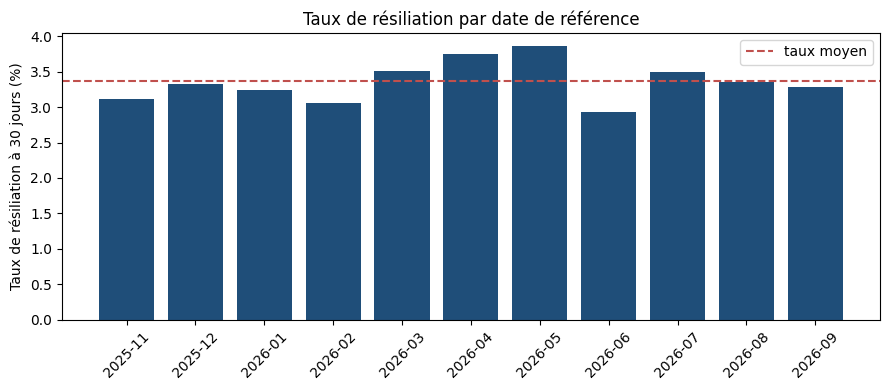

,lignes,résiliations,taux
date_reference,,,
2025-11-01,3117,97,3.11
2025-12-01,3217,107,3.33
2026-01-01,3327,108,3.25
2026-02-01,3397,104,3.06
2026-03-01,3471,122,3.51
2026-04-01,3546,133,3.75
2026-05-01,3604,139,3.86
2026-06-01,3646,107,2.93
2026-07-01,3743,131,3.50


In [7]:
par_mois = df.groupby("date_reference")[CIBLE].agg(["count", "sum", "mean"])
par_mois.columns = ["lignes", "résiliations", "taux"]

fig, ax = plt.subplots()
ax.bar(par_mois.index.strftime("%Y-%m"), par_mois["taux"] * 100, color="#1F4E79")
ax.axhline(df[CIBLE].mean() * 100, color="#C0504D", linestyle="--", label="taux moyen")
ax.set_ylabel("Taux de résiliation à 30 jours (%)")
ax.set_title("Taux de résiliation par date de référence")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
par_mois.assign(taux=lambda t: (t["taux"] * 100).round(2))

**Constat.** Les résiliations ne représentent qu'environ 3 % des lignes, avec un taux assez stable
d'un mois à l'autre. Conséquences pour la modélisation :

- l'exactitude (accuracy) n'est pas une bonne mesure : prédire « jamais de résiliation » donnerait
  déjà environ 97 % de bonnes réponses. `evaluation.py` utilise donc l'AUC ROC, l'AUC PR et la part
  des départs captés en contactant 10 % des clients ;
- certains modèles seront testés avec une pondération des classes (`class_weight`).

## 4. Variables numériques : clients partis et clients restés

In [8]:
numeriques = ["prix_mensuel", "anciennete_jours", "sessions_30j", "sessions_30_60j", "evolution_sessions",
              "supports_30j", "reclamations_30j", "jours_depuis_derniere_session"]
comparaison = df.groupby(CIBLE)[numeriques].mean().T
comparaison.columns = ["restés (0)", "partis (1)"]
comparaison["écart relatif (%)"] = ((comparaison["partis (1)"] / comparaison["restés (0)"] - 1) * 100).round(1)
comparaison.round(3)

,restés (0),partis (1),écart relatif (%)
prix_mensuel,13.310,12.639,-5.0
anciennete_jours,414.443,419.049,1.1
sessions_30j,10.532,7.602,-27.8
sessions_30_60j,9.230,9.021,-2.3
evolution_sessions,0.525,0.043,-91.8
supports_30j,0.245,0.941,284.3
reclamations_30j,0.092,0.347,276.3
jours_depuis_derniere_session,5.206,8.161,56.8


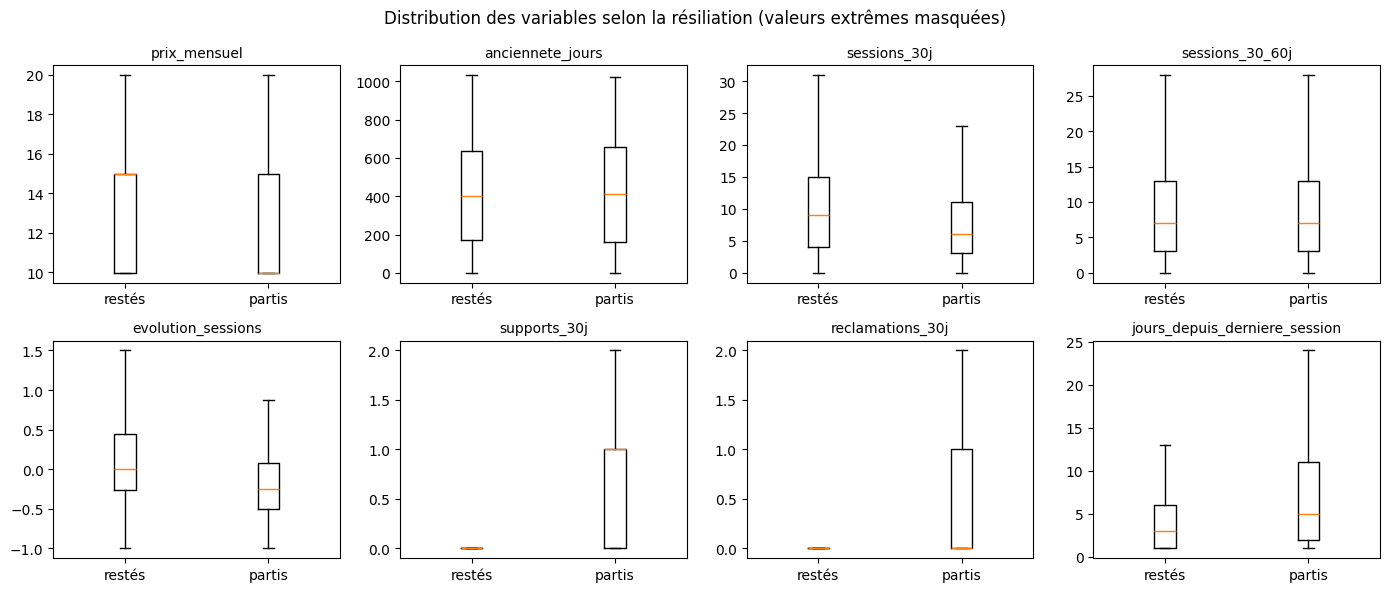

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, variable in zip(axes.ravel(), numeriques):
    donnees = [df.loc[df[CIBLE] == k, variable].dropna() for k in (0, 1)]
    ax.boxplot(donnees, showfliers=False)
    ax.set_xticks([1, 2], ["restés", "partis"])
    ax.set_title(variable, fontsize=10)
fig.suptitle("Distribution des variables selon la résiliation (valeurs extrêmes masquées)")
plt.tight_layout()
plt.show()

**Constat.** Les clients qui résilient ont moins de sessions sur les trente derniers jours, une
évolution de l'usage plus faible, davantage de demandes au support et de réclamations, et une
dernière session plus ancienne. L'ancienneté et les sessions entre 30 et 60 jours distinguent peu
les deux groupes : la sélection des variables (`selection.py`) le vérifie par des tests statistiques.

## 5. Variables catégorielles

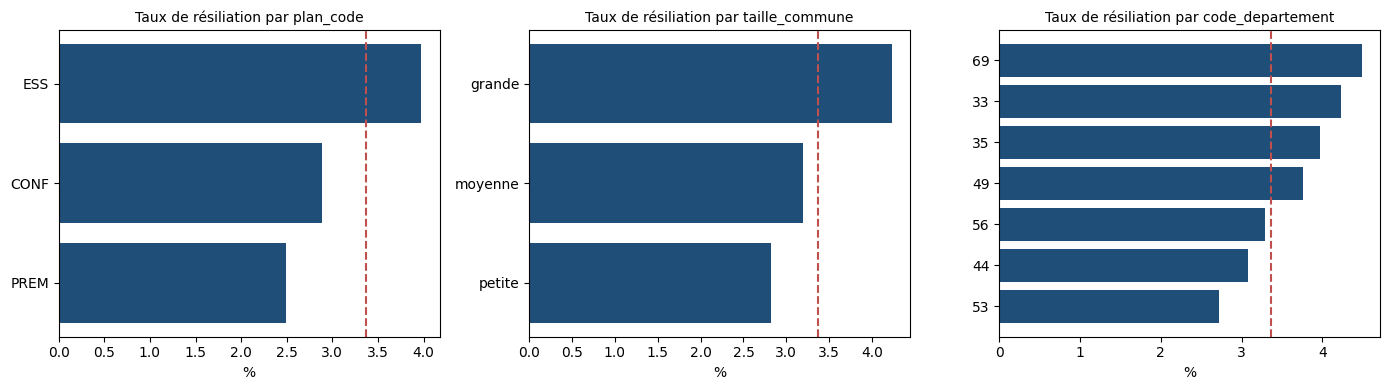

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, variable in zip(axes, ["plan_code", "taille_commune", "code_departement"]):
    taux = df.groupby(variable)[CIBLE].mean().sort_values() * 100
    ax.barh(taux.index.astype(str), taux.values, color="#1F4E79")
    ax.axvline(df[CIBLE].mean() * 100, color="#C0504D", linestyle="--")
    ax.set_title(f"Taux de résiliation par {variable}", fontsize=10)
    ax.set_xlabel("%")
plt.tight_layout()
plt.show()

In [11]:
df.groupby("taille_commune")[CIBLE].agg(lignes="count", taux="mean").assign(taux=lambda t: (t["taux"] * 100).round(2))

,lignes,taux
taille_commune,,
grande,11522,4.23
moyenne,12425,3.20
petite,14548,2.83


In [12]:
# Chaque formule correspond à un seul prix : les deux colonnes portent la même information
df.groupby("plan_code")["prix_mensuel"].unique()

plan_code
CONF    [14.99]
ESS      [9.99]
PREM    [19.99]
Name: prix_mensuel, dtype: object

**Constat.** Le taux de résiliation augmente avec la taille de la commune, ce qui confirme
l'hypothèse posée au Bloc 1. La formule et le prix mensuel sont redondants (un prix par formule) :
une seule des deux variables doit être gardée.

## 6. Relations entre variables

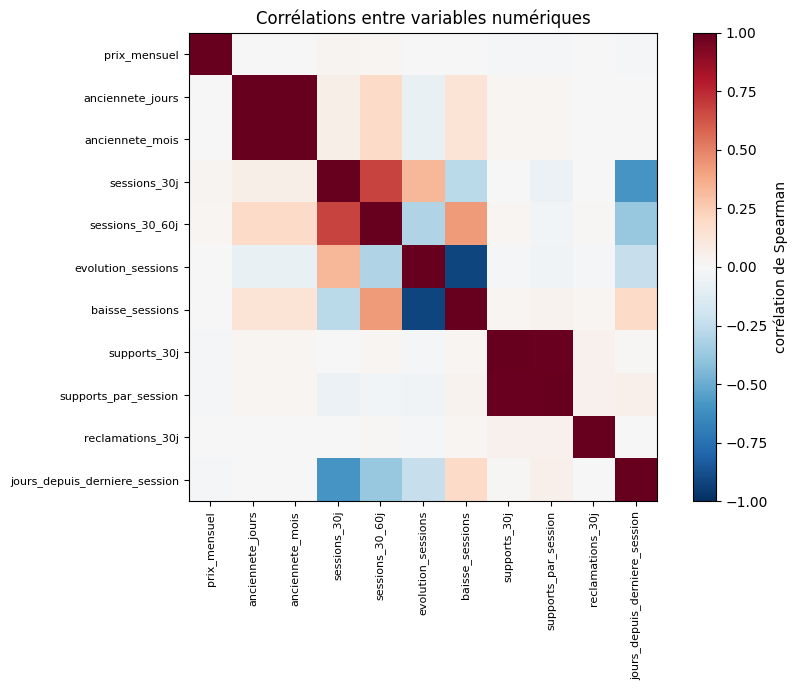

In [13]:
x = construire(df)
candidates = ["prix_mensuel", "anciennete_jours", "anciennete_mois", "sessions_30j", "sessions_30_60j",
              "evolution_sessions", "baisse_sessions", "supports_30j", "supports_par_session",
              "reclamations_30j", "jours_depuis_derniere_session"]
correlations = x[candidates].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(candidates)), candidates, rotation=90, fontsize=8)
ax.set_yticks(range(len(candidates)), candidates, fontsize=8)
fig.colorbar(image, label="corrélation de Spearman")
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

In [14]:
paires = (correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1)).stack()
          .rename("corrélation").to_frame())
paires[paires["corrélation"].abs() > 0.8].sort_values("corrélation", ascending=False).round(3)

,,corrélation
anciennete_jours,anciennete_mois,1.000
supports_30j,supports_par_session,0.989
evolution_sessions,baisse_sessions,-0.919


**Constat.** Certaines variables construites répètent une variable existante (l'ancienneté en mois
et en jours, les supports par session et le nombre de supports). Garder les deux n'apporte rien au
modèle et rend ses coefficients instables : `selection.py` écarte automatiquement la moins
informative de chaque paire au-delà de 0,95.

La paire `evolution_sessions` et `baisse_sessions` (environ −0,92) reste sous ce seuil : les deux
variables sont gardées, car l'une mesure une variation relative de l'usage et l'autre une variation
en nombre de sessions, ce qui n'a pas le même sens pour un client peu actif et pour un client très actif.

## 7. Stabilité des données dans le temps

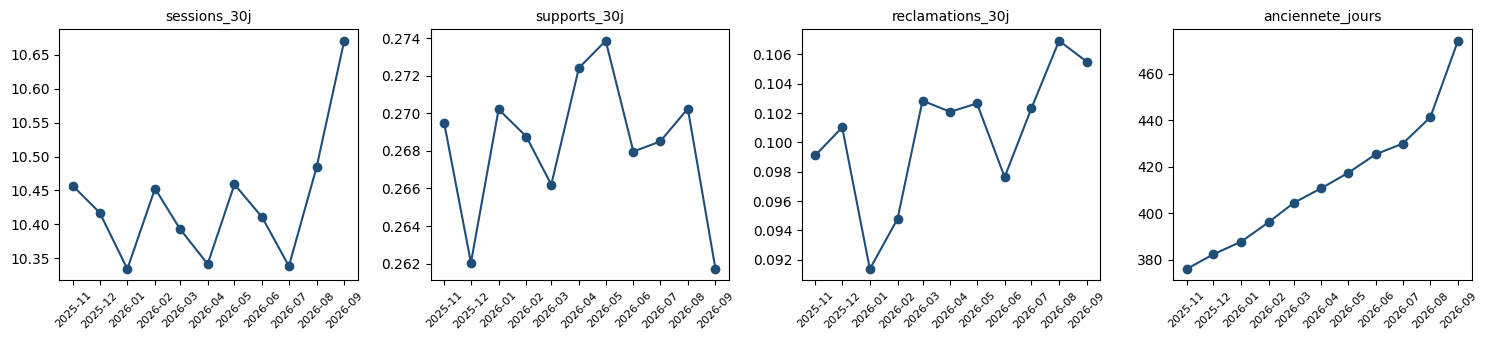

In [15]:
suivi = df.groupby("date_reference")[["sessions_30j", "supports_30j", "reclamations_30j", "anciennete_jours"]].mean()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, variable in zip(axes, suivi.columns):
    ax.plot(suivi.index, suivi[variable], marker="o", color="#1F4E79")
    ax.set_title(variable, fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
plt.tight_layout()
plt.show()

**Constat.** Les comportements d'usage restent stables d'un mois à l'autre. L'ancienneté moyenne,
elle, augmente naturellement avec le temps : c'est une évolution attendue, que la surveillance du
modèle (`surveillance.py`, indice PSI) doit suivre pour repérer un changement anormal.

## 8. Clients suivis sur plusieurs mois

In [16]:
mois_par_client = df.groupby("client_pseudo")["date_reference"].nunique()
mois_par_client.value_counts().sort_index().rename("clients").to_frame()

,clients
date_reference,
1,155
2,309
3,336
4,297
5,296
6,281
7,261
8,229
9,263


**Constat.** Un même client apparaît à plusieurs dates de référence. Un découpage aléatoire des
lignes mettrait donc des informations sur un même client et sur une même période à la fois dans
l'apprentissage et dans le test. Le Bloc 5 découpe par période : apprentissage jusqu'en mai 2026,
validation en juin et juillet, test en août et septembre. Le modèle est ainsi évalué comme il sera
utilisé, sur des mois qu'il n'a jamais vus.

## 9. Synthèse et choix de modélisation

| Constat | Choix dans le Bloc 5 |
| --- | --- |
| Environ 3 % de résiliations | Mesures AUC ROC, AUC PR et campagne à 10 % (`evaluation.py`), pondération des classes testée |
| Valeurs manquantes porteuses de sens | Indicateurs dédiés et valeur explicite plutôt que zéro (`variables.py`) |
| Usage, support et réclamations distinguent les deux groupes | Variables dérivées : baisse des sessions, inactivité, réclamation récente |
| Variables redondantes | Écartées automatiquement (`selection.py`) |
| Effet de la taille de la commune | Variable conservée et testée |
| Clients présents sur plusieurs mois, données datées | Découpage temporel et validation croisée glissante (`donnees.py`, `optimisation.py`) |
| Évolutions possibles dans le temps | Surveillance de la dérive et de la performance (`surveillance.py`) |